# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [ ]:
import pandas as pd
import plotly.express as px


# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

In [1]:
import pandas as pd
import plotly.express as px

# Load the Gapminder dataset
df = px.data.gapminder()

print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [ ]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


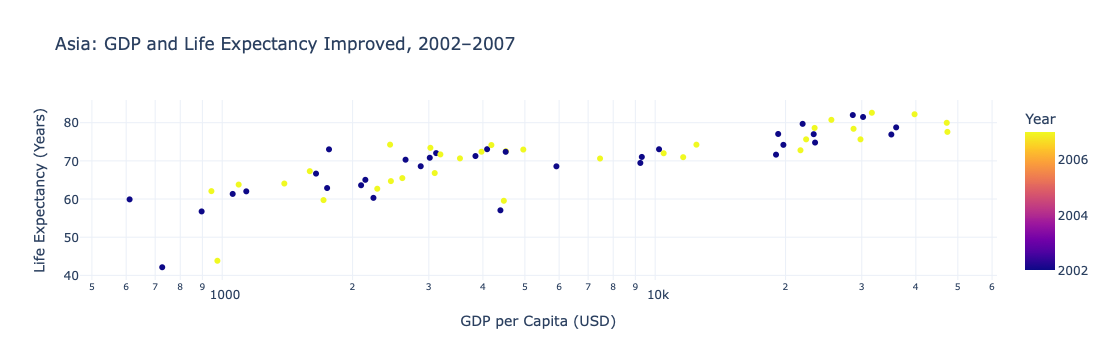

In [2]:
# Task 1
# YOUR CODE HERE

# Task 1: Scatter chart

asia = df.loc[
    (df["continent"] == "Asia") &
    (df["year"].isin([2002, 2007]))
].copy()

fig = px.scatter(
    asia,
    x="gdpPercap",
    y="lifeExp",
    color="year",
    color_discrete_map={
        2002: "#9ECAE1",
        2007: "#08519C"
    },
    hover_name="country",
    title="Asia: GDP and Life Expectancy Improved, 2002–2007",
    labels={
        "gdpPercap": "GDP per Capita (USD)",
        "lifeExp": "Life Expectancy (Years)",
        "year": "Year"
    }
)

fig.update_xaxes(type="log")
fig.update_layout(template="plotly_white")
fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


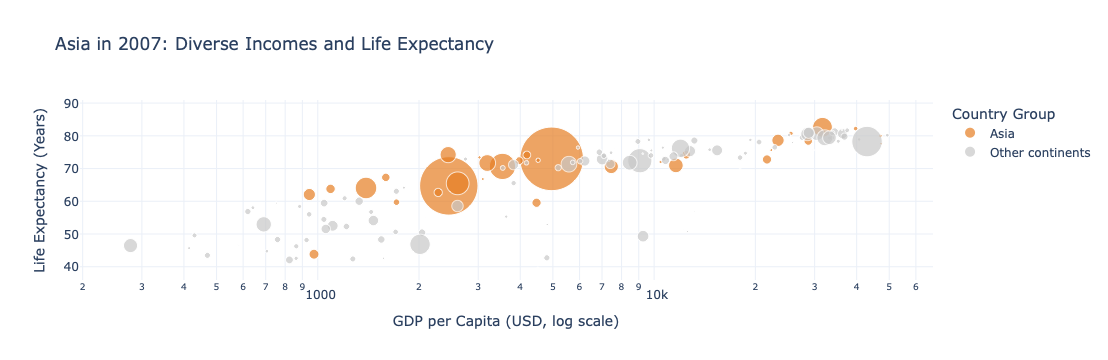

In [5]:
# Task 2
# YOUR CODE HERE

# Task 2: Bubble chart

df_2007 = df.loc[df["year"] == 2007].copy()

df_2007["Group"] = df_2007["continent"].apply(
    lambda continent: "Asia" if continent == "Asia"
    else "Other continents"
)

fig = px.scatter(
    df_2007,
    x="gdpPercap",
    y="lifeExp",
    size="pop",
    size_max=45,
    color="Group",
    color_discrete_map={
        "Asia": "#E67E22",
        "Other continents": "#C7C7C7"
    },
    hover_name="country",
    hover_data=["continent", "pop", "gdpPercap", "lifeExp"],
    log_x=True,
    title="Asia in 2007: Diverse Incomes and Life Expectancy",
    labels={
        "gdpPercap": "GDP per Capita (USD, log scale)",
        "lifeExp": "Life Expectancy (Years)",
        "pop": "Population",
        "Group": "Country Group"
    }
)

fig.update_layout(template="plotly_white")

fig.add_annotation(
    x=5000,
    y=72,
    text="Asia has a wide range of incomes<br>and life expectancies",
    showarrow=True,
    arrowhead=2,
    ax=60,
    ay=-45,
    bgcolor="white"
)

fig.show()




In [4]:
import pandas as pd
import plotly.express as px

df = px.data.gapminder()
